EDA AND FEATURE ENGINEERING

In [1]:
#  IMPORT LIBRARIES
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Create an output folder to store graphs and results
os.makedirs("outputs", exist_ok=True)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# LOAD THE DATASET

df = pd.read_excel("P719-Dataset.xlsx")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Number of rows: 1440
Number of columns: 3


,title,rating,body
0,Horrible product,1,Very disappointed with the overall performance...
1,Camera quality is not like 48 megapixel,3,Camera quality is low
2,Overall,4,"Got the mobile on the launch date,Battery must..."
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp..."


In [3]:
#  DATASET INFORMATION

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all"))

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (1440, 3)

Column names:
['title', 'rating', 'body']

Data types:
title     object
rating     int64
body      object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   title   1440 non-null   object
 1   rating  1440 non-null   int64 
 2   body    1440 non-null   object
dtypes: int64(1), object(2)
memory usage: 33.9+ KB

Statistical summary:


,title,rating,body
count,1440,1440.000000,1440
unique,1351,NaN,1440
top,Value for money,NaN,Front camera refresh rate is low.Bloatwares an...
freq,16,NaN,1
mean,NaN,3.173611,NaN
std,NaN,1.584453,NaN
min,NaN,1.000000,NaN
25%,NaN,1.000000,NaN
50%,NaN,4.000000,NaN
75%,NaN,5.000000,NaN



Missing values:
title     0
rating    0
body      0
dtype: int64

Duplicate rows: 0


In [4]:
#  DATA CLEANING

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Handle missing text values
df["title"] = df["title"].fillna("").astype(str).str.strip()
df["body"] = df["body"].fillna("").astype(str).str.strip()

# Convert ratings to numeric values
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")

# Keep only valid ratings from 1 to 5
df = df.dropna(subset=["rating"])
df = df[df["rating"].between(1, 5)].copy()
df = df[df["rating"] % 1 == 0].copy()

# Combine review title and body
df["review_text"] = (
    df["title"] + " " + df["body"]
).str.strip()

# Remove empty reviews
df = df[df["review_text"] != ""].copy()

df.reset_index(drop=True, inplace=True)

print("Dataset cleaned successfully!")
print("Remaining reviews:", len(df))
display(df.head())

Dataset cleaned successfully!
Remaining reviews: 1440


,title,rating,body,review_text
0,Horrible product,1,Very disappointed with the overall performance...,Horrible product Very disappointed with the ov...
1,Camera quality is not like 48 megapixel,3,Camera quality is low,Camera quality is not like 48 megapixel Camera...
2,Overall,4,"Got the mobile on the launch date,Battery must...","Overall Got the mobile on the launch date,Batt..."
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....,A big no from me 1. It doesn't work with 5.0GH...
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp...",Put your money somewhere else Not worth buying...


In [5]:
#  CREATE SENTIMENT LABELS

def rating_to_sentiment(rating):
    if rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    else:
        return "Positive"

df["sentiment"] = df["rating"].apply(rating_to_sentiment)

print("Sentiment labels created successfully!")
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

display(df[["rating", "review_text", "sentiment"]].head(10))

Sentiment labels created successfully!

Sentiment distribution:
sentiment
Positive    729
Negative    512
Neutral     199
Name: count, dtype: int64


,rating,review_text,sentiment
0,1,Horrible product Very disappointed with the ov...,Negative
1,3,Camera quality is not like 48 megapixel Camera...,Neutral
2,4,"Overall Got the mobile on the launch date,Batt...",Positive
3,1,A big no from me 1. It doesn't work with 5.0GH...,Negative
4,1,Put your money somewhere else Not worth buying...,Negative
5,1,Too much lagging and slow I will never purchas...,Negative
6,1,Worst samsung mobile ever This is worst samsun...,Negative
7,1,कैसा दिखाते है उसका 10 % भी नही मोबाइल का कैमर...,Negative
8,1,Slow performance The phone hangs a lot and is ...,Negative
9,1,Don’t buy from Amazon. Very poor quality camer...,Negative


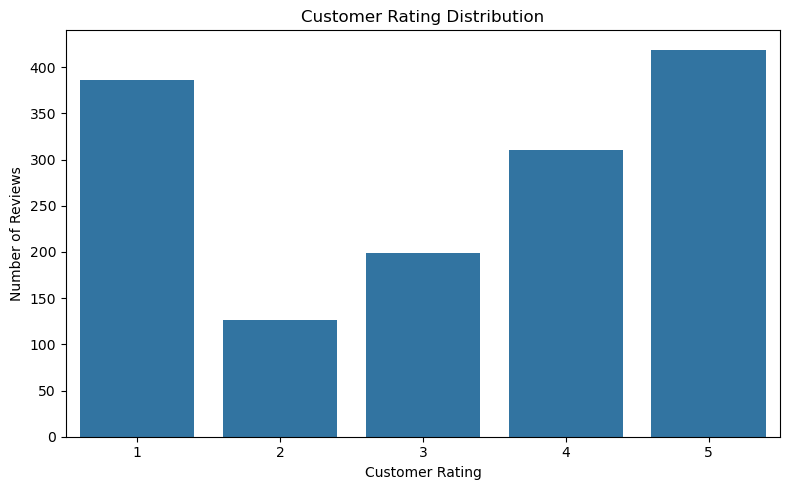

In [6]:
#  RATING DISTRIBUTION

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="rating",
    order=[1, 2, 3, 4, 5]
)

plt.title("Customer Rating Distribution")
plt.xlabel("Customer Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()

plt.savefig("outputs/rating_distribution.png", dpi=150)
plt.show()

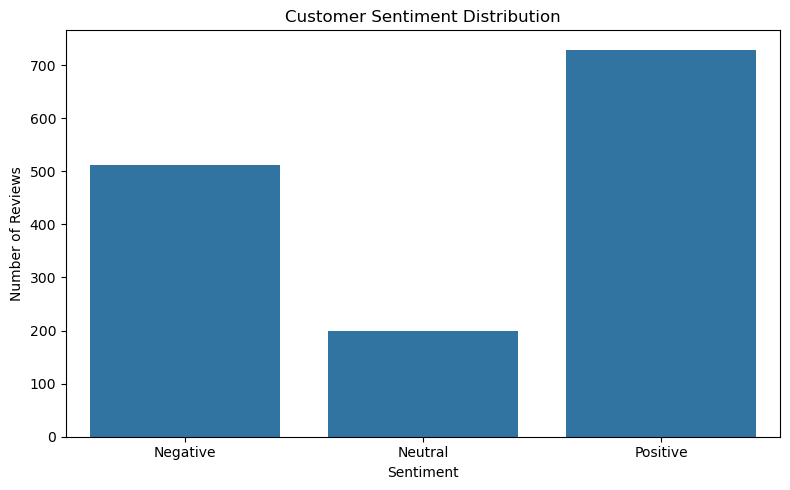

In [7]:
#  SENTIMENT DISTRIBUTION

sentiment_order = ["Negative", "Neutral", "Positive"]

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="sentiment",
    order=sentiment_order
)

plt.title("Customer Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()

plt.savefig("outputs/sentiment_distribution.png", dpi=150)
plt.show()

Review length statistics:


count    1440.000000
mean       58.257639
std        39.896874
min         2.000000
25%        34.000000
50%        49.000000
75%        70.000000
max       391.000000
Name: word_count, dtype: float64

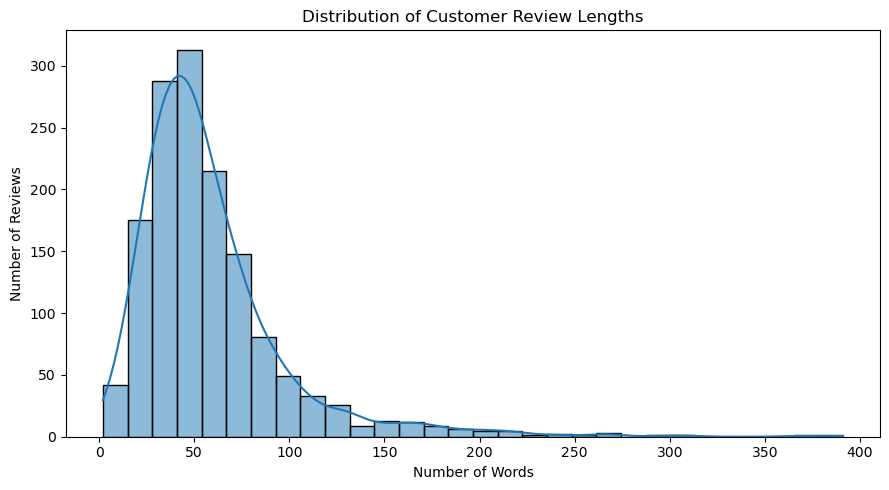

In [8]:
#  REVIEW LENGTH ANALYSIS

df["word_count"] = df["review_text"].str.split().str.len()

print("Review length statistics:")
display(df["word_count"].describe())

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="word_count",
    bins=30,
    kde=True
)

plt.title("Distribution of Customer Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.tight_layout()

plt.savefig("outputs/review_length_distribution.png", dpi=150)
plt.show()

In [9]:
#  SAVE CLEANED DATASET

df.to_csv("cleaned_reviews.csv", index=False)

print("Cleaned dataset saved as cleaned_reviews.csv")
print("EDA graphs saved in the outputs folder.")

Cleaned dataset saved as cleaned_reviews.csv
EDA graphs saved in the outputs folder.


MODEL BUILDING AND MODEL EVALUTION

In [10]:
#  IMPORT MACHINE LEARNING LIBRARIES

import joblib
import json

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Machine learning libraries imported successfully!")

Machine learning libraries imported successfully!


In [11]:
#  PREPARE TRAINING AND TESTING DATA

df = pd.read_csv("cleaned_reviews.csv")

X = df["review_text"].astype(str)
y = df["sentiment"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())

Training samples: 1152
Testing samples: 288

Training sentiment distribution:
sentiment
Positive    583
Negative    410
Neutral     159
Name: count, dtype: int64

Testing sentiment distribution:
sentiment
Positive    146
Negative    102
Neutral      40
Name: count, dtype: int64


In [12]:
#  DEFINE MACHINE LEARNING MODELS

models = {
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            stop_words="english",
            ngram_range=(1, 2),
            max_features=20000,
            min_df=2,
            sublinear_tf=True
        )),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        ))
    ]),

    "Multinomial Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            stop_words="english",
            ngram_range=(1, 2),
            max_features=20000,
            min_df=2
        )),
        ("classifier", MultinomialNB())
    ]),

    "Linear SVM": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            stop_words="english",
            ngram_range=(1, 2),
            max_features=20000,
            min_df=2,
            sublinear_tf=True
        )),
        ("classifier", LinearSVC(
            class_weight="balanced"
        ))
    ])
}

print("Three models defined successfully!")

Three models defined successfully!


In [13]:
# TRAIN MODELS AND CALCULATE METRICS

results = []
trained_models = {}
predictions_by_model = {}

for model_name, model in models.items():

    print("\n" + "=" * 60)
    print("MODEL:", model_name)
    print("=" * 60)

    # Train the model
    model.fit(X_train, y_train)

    # Predict sentiment for test reviews
    y_pred = model.predict(X_test)

    trained_models[model_name] = model
    predictions_by_model[model_name] = y_pred

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print(f"Accuracy : {accuracy:.4f} ({accuracy * 100:.2f}%)")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1 Score : {f1:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=["Negative", "Neutral", "Positive"],
        zero_division=0
    ))


MODEL: Logistic Regression
Accuracy : 0.7535 (75.35%)
Precision: 0.7359
Recall   : 0.7535
F1 Score : 0.7439

Classification Report:
              precision    recall  f1-score   support

    Negative       0.79      0.80      0.80       102
     Neutral       0.26      0.20      0.23        40
    Positive       0.83      0.87      0.85       146

    accuracy                           0.75       288
   macro avg       0.63      0.62      0.62       288
weighted avg       0.74      0.75      0.74       288


MODEL: Multinomial Naive Bayes
Accuracy : 0.7500 (75.00%)
Precision: 0.6548
Recall   : 0.7500
F1 Score : 0.6910

Classification Report:
              precision    recall  f1-score   support

    Negative       0.82      0.72      0.76       102
     Neutral       0.00      0.00      0.00        40
    Positive       0.72      0.98      0.83       146

    accuracy                           0.75       288
   macro avg       0.51      0.57      0.53       288
weighted avg       0.65

,Model,Accuracy,Precision,Recall,F1 Score
0,Linear SVM,0.7812,0.7445,0.7812,0.7575
1,Logistic Regression,0.7535,0.7359,0.7535,0.7439
2,Multinomial Naive Bayes,0.7500,0.6548,0.7500,0.6910


<Figure size 1000x500 with 0 Axes>

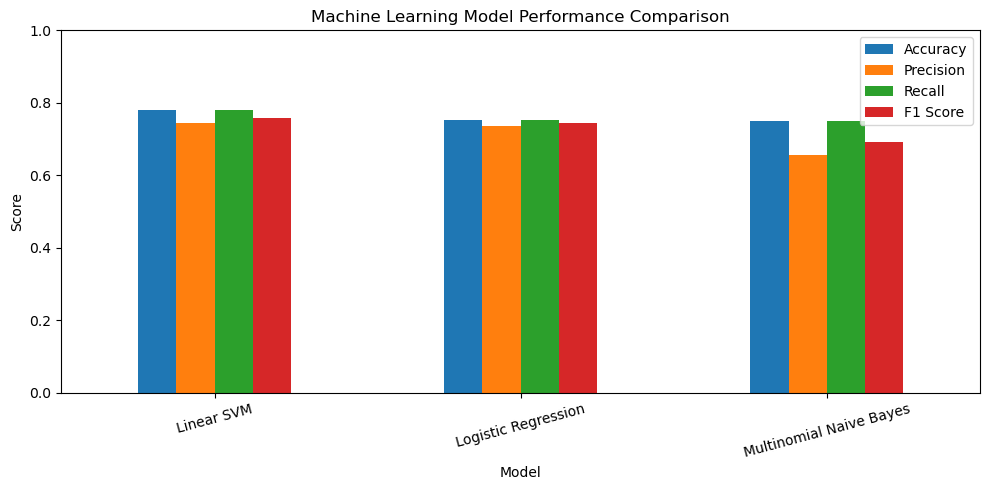

In [14]:
# COMPARE ALL MODELS

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

results_df.to_csv(
    "outputs/model_comparison.csv",
    index=False
)

plt.figure(figsize=(10, 5))

results_plot = results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
]

results_plot.plot(kind="bar", figsize=(10, 5))

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig("outputs/model_comparison.png", dpi=150)
plt.show()

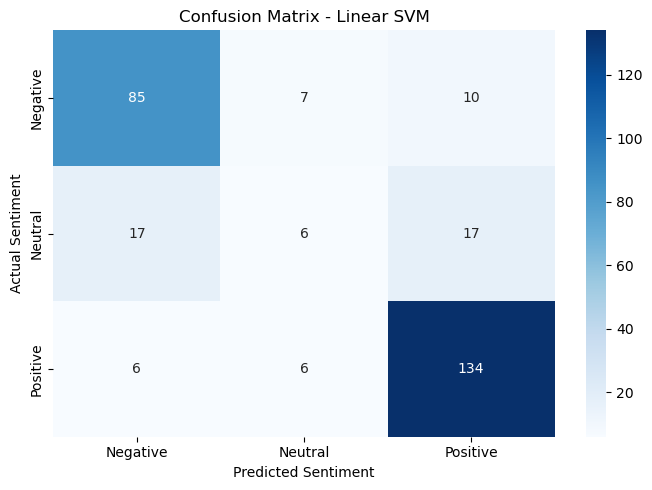

Best model selected: Linear SVM


In [15]:
#  BEST MODEL CONFUSION MATRIX

best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]
y_pred_best = predictions_by_model[best_model_name]

labels = ["Negative", "Neutral", "Positive"]

cm = confusion_matrix(
    y_test,
    y_pred_best,
    labels=labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.tight_layout()

plt.savefig("outputs/best_model_confusion_matrix.png", dpi=150)
plt.show()

print("Best model selected:", best_model_name)

In [16]:
#  SAVE BEST MODEL AND EVALUATION RESULTS

joblib.dump(best_model, "sentiment_model.joblib")

best_accuracy = accuracy_score(y_test, y_pred_best)

best_report = classification_report(
    y_test,
    y_pred_best,
    labels=["Negative", "Neutral", "Positive"],
    output_dict=True,
    zero_division=0
)

evaluation_results = {
    "best_model": best_model_name,
    "accuracy": float(best_accuracy),
    "classification_report": best_report
}

with open(
    "outputs/best_model_report.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(evaluation_results, file, indent=4)

print("Best model:", best_model_name)
print(f"Test accuracy: {best_accuracy * 100:.2f}%")
print("Saved model: sentiment_model.joblib")

Best model: Linear SVM
Test accuracy: 78.12%
Saved model: sentiment_model.joblib


DEPLOYMENT

In [17]:
#  CREATE STREAMLIT WEB APPLICATION

app_code = r'''
import os
import pandas as pd
import streamlit as st
import joblib

st.set_page_config(
    page_title="NLP Sentiment Analysis",
    page_icon="💬",
    layout="wide"
)

st.title("NLP Sentiment Analysis")
st.write("Analyze customer reviews using machine learning.")

# Load the trained model
if not os.path.exists("sentiment_model.joblib"):
    st.error("Model not found. Complete WEEK 2 training first.")
    st.stop()

model = joblib.load("sentiment_model.joblib")

# Create application tabs
tab1, tab2 = st.tabs([
    "Sentiment Prediction",
    "Dataset Analysis"
])

#  SENTIMENT PREDICTION
with tab1:
    st.subheader("Enter Customer Review")

    review = st.text_area(
        "Customer review",
        placeholder="The product is excellent..."
    )

    if st.button("Analyze Sentiment"):
        if not review.strip():
            st.warning("Please enter a review.")
        else:
            prediction = model.predict([review.strip()])[0]

            if prediction == "Positive":
                st.success("Sentiment: Positive")
            elif prediction == "Negative":
                st.error("Sentiment: Negative")
            else:
                st.info("Sentiment: Neutral")

#  DATASET ANALYSIS
with tab2:
    st.subheader("Customer Review Analysis")

    if os.path.exists("cleaned_reviews.csv"):
        df = pd.read_csv("cleaned_reviews.csv")

        st.metric("Total Reviews", len(df))

        st.write("Sentiment Distribution")
        st.bar_chart(df["sentiment"].value_counts())

        st.write("Sample Reviews")
        st.dataframe(
            df[["rating", "review_text", "sentiment"]].head(20),
            use_container_width=True
        )
    else:
        st.warning("Run to create the cleaned dataset.")
'''

with open("app.py", "w", encoding="utf-8") as file:
    file.write(app_code)

print(" app.py created successfully!")

 app.py created successfully!


In [18]:
#  LAUNCH STREAMLIT APPLICATION

%pip install streamlit

In [ ]:
# START WEB APPLICATION

### !streamlit run app.py